<font size="+3">Monitor : BindCraft Designs in Funnel Metadynamics  </font>


In [2]:
import pandas as pd
import numpy as np
import os

import warnings
warnings.simplefilter("ignore")
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import seaborn as sns
import shutil
import glob

from scipy.spatial.distance import cdist

from Bio.SeqUtils import seq1

from pandas.api.types import CategoricalDtype
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score

import json
from pathlib import Path


In [ ]:
df1 = pd.read_csv('/Volumes/LaCie/250523_bindcraft_funnel_metadynamics_rmsd-restraint/deltaG.csv')
df2 = pd.read_csv('/Volumes/LaCie/250527_bindcraft_funnel_metadynamics_batch2/deltaG.csv')

targets = ["BBF-14", "IFNAR2", "DerF7", "DerF21"]
#targets = ["BBF-14", "IFNAR2", "DerF7"]
df = pd.concat([df1, df2], ignore_index=True)

df = df[df["binder"].str.contains("|".join(targets), na=False)].reset_index(drop=True)

df.to_pickle("deltaG.pkl")

In [5]:
PREDICTORS = {                                # dir -> pretty name (fixed order: AF3, ESMFold2, Protenix-v2, OpenDDE)
    "AF3":         "AF3",
    "ESMFold2":    "ESMFold2",
    "Protenix_v2": "Protenix-v2",
    "OpenDDE":     "OpenDDE",
}
TARGETS = ["BBF-14", "IFNAR2", "DerF7", "DerF21"]
TARGET_DIR = {                                # target -> subdir under each predictor (BBF-14 folder carries a suffix)
    "BBF-14": "BBF-14_noMSA",
    "IFNAR2": "IFNAR2",
    "DerF7":  "DerF7",
    "DerF21": "DerF21",
}
EXCLUDE = {"BBF-14_b5", "BBF-14_b7"}          # His-Tag at interface


In [6]:
# labels (target, design, Type) from the per-target CSVs
labels = []
for t in TARGETS:
    df = pd.read_csv(f"{t}.csv").rename(columns={"Design": "design"})
    df["target"] = t
    labels.append(df[["target", "design", "Type"]])
labels = pd.concat(labels, ignore_index=True)

# BBF-14 subdir differs by predictor: ESMFold2 uses BBF-14_noMSA, the others use BBF-14_noMSA_template
def target_subdir(pdir, target):
    if target == "BBF-14" and pdir != "ESMFold2":
        return "BBF-14_noMSA_template"
    return TARGET_DIR[target]

# ipTM scores — read `iptm` from each method's output.csv, averaged across the 3 seeds -> one value per design
def load_all():
    rows = []
    for pdir, pname in PREDICTORS.items():
        for target in TARGETS:
            out = Path(pdir) / target_subdir(pdir, target) / "output.csv"
            if not out.exists():
                print("missing", out); continue
            o = pd.read_csv(out)
            o = (o.groupby("ID", as_index=False)["iptm"].mean()      # mean over seeds
                   .rename(columns={"ID": "design"}))
            o["predictor"] = pname
            o["target"]    = target
            rows.append(o)
    df = pd.concat(rows, ignore_index=True)
    return df.merge(labels, on=["target", "design"], how="left")

res = load_all()

# MD ΔG (deltaG.pkl): batch -> Type; target by substring; average across MD replicas -> one value per design
md = pd.read_pickle("deltaG.pkl").rename(columns={"binder": "design"})
md["Type"]   = md["batch"].map({"binders": "binder", "decoys": "decoy"})
md["target"] = md["design"].apply(lambda s: next((t for t in TARGETS if t in s), np.nan))
md = md[np.isfinite(md["deltaG"])]                              # drop non-finite ΔG rows (+inf unbinding reps)
md = md.groupby(["design", "target", "Type"], as_index=False)["deltaG"].mean()

# drop excluded designs from every panel
res = res[~res.design.isin(EXCLUDE)].reset_index(drop=True)
md  = md[~md.design.isin(EXCLUDE)].reset_index(drop=True)

# keep only designs that have at least one (finite) MD ΔG value
# `md` already holds one row per design with >=1 finite ΔG, so its designs are the reference set
designs_with_dG = set(md["design"])
res = res[res.design.isin(designs_with_dG)].reset_index(drop=True)


In [7]:
def compute_metrics(y, score):
    y = np.asarray(y).astype(int)
    if len(np.unique(y)) < 2:
        return dict(AP=np.nan, AUC=np.nan, AUC01=np.nan)
    return dict(AP=average_precision_score(y, score),
                AUC=roc_auc_score(y, score),
                AUC01=roc_auc_score(y, score, max_fpr=0.1))   # partial AUC to FPR=0.1

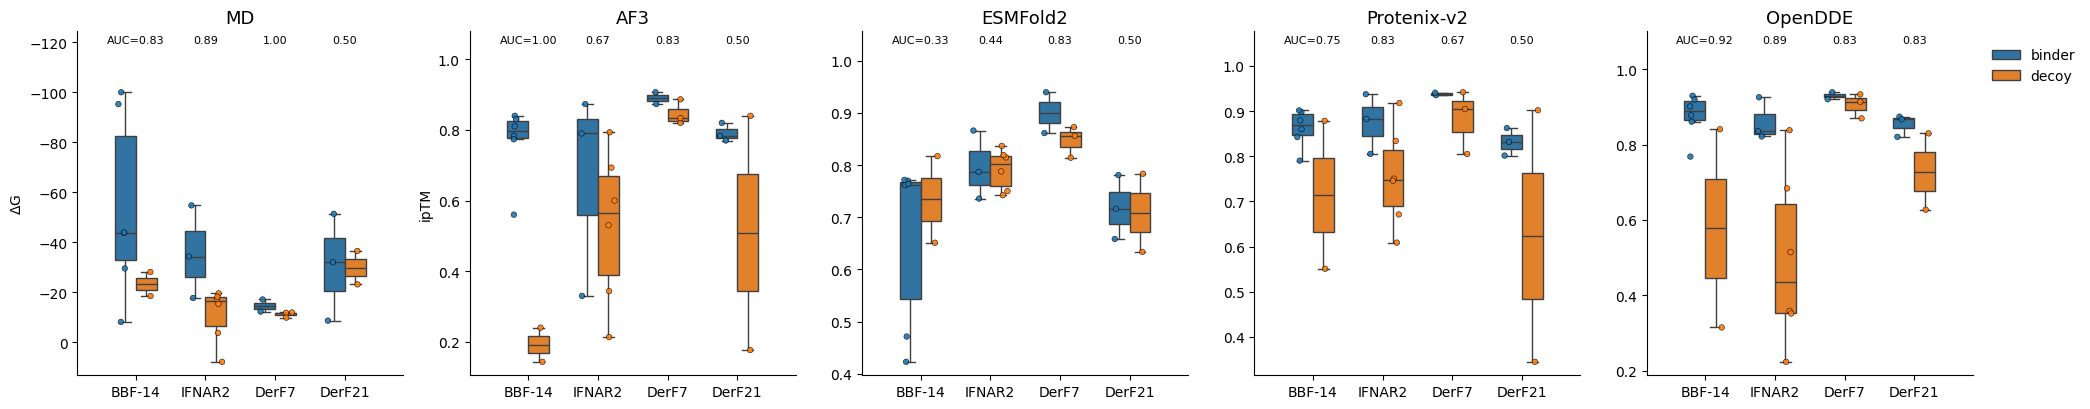

In [8]:
# panel spec: (title, dataframe, y-column, invert y?, score sign for metrics)
panels = [("MD", md, "deltaG", True, -1.0)]                    # lower ΔG = better binder
panels += [(p, res[res.predictor == p], "iptm", False, 1.0)
           for p in PREDICTORS.values()]

ylabel = {"deltaG": r"$\Delta$G", "iptm": "ipTM"}

fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.2), sharey=False)
if len(panels) == 1:
    axes = [axes]

for ax, (title, sub, ycol, invert, sign) in zip(axes, panels):
    sns.boxplot(sub, x="target", y=ycol, hue="Type", order=TARGETS,
                hue_order=["binder", "decoy"], showfliers=False, width=0.6, ax=ax)
    sns.stripplot(sub, x="target", y=ycol, hue="Type", order=TARGETS,
                  hue_order=["binder", "decoy"], dodge=True, size=4,
                  edgecolor="black", linewidth=0.4, alpha=0.9, ax=ax, legend=False)

    if invert:
        ax.invert_yaxis()
    # headroom at the visual top, works for normal and inverted axes
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + (y1 - y0) * 0.16)        # one line of text now, not two

    # AUC per target, at the visual top of the panel
    trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    for i, t in enumerate(TARGETS):
        s = sub[sub.target == t]
        m = compute_metrics(s.Type == "binder", sign * s[ycol])
        if np.isfinite(m["AUC"]):
            # spell out the label only on the leftmost group; numbers only for the rest
            txt = (f"AUC={m['AUC']:.2f}" if i == 0 else f"{m['AUC']:.2f}")
            ax.text(i, 0.99, txt,
                    transform=trans, ha="center", va="top", fontsize=8)

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel[ycol] if ax in (axes[0], axes[1]) else "")
    ax.margins(x=0.15)

    if ax is axes[-1]:
        h, l = ax.get_legend_handles_labels()
        ax.legend(h[:2], l[:2], loc="center left",
                  bbox_to_anchor=(1.02, 0.9), frameon=False, title="")
    elif ax.legend_ is not None:
        ax.legend_.remove()

sns.despine(fig)
fig.tight_layout()
plt.show()

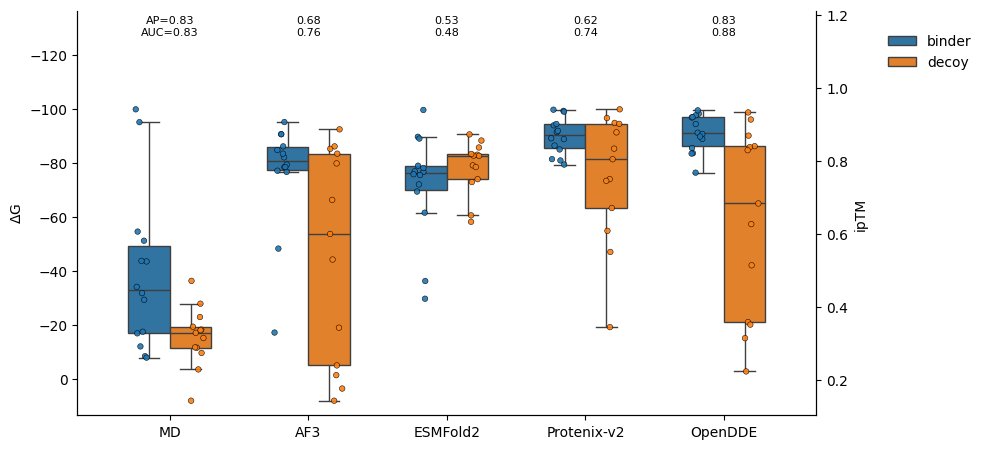

In [10]:
# ---- pooled panel, raw units, dual axis ------------------------------------
METHODS     = ["MD"] + list(PREDICTORS.values())
METRIC_MODE = "within_target"      # or "pooled_raw"

long = pd.concat([
    md.assign(method="MD", value=md["deltaG"], score=-md["deltaG"])
      [["design", "target", "Type", "method", "value", "score"]],
    res.rename(columns={"predictor": "method"})
       .assign(value=lambda d: d["iptm"], score=lambda d: d["iptm"])
       [["design", "target", "Type", "method", "value", "score"]],
], ignore_index=True)
long["y"]    = (long.Type == "binder").astype(int)
long["rank"] = long.groupby(["method", "target"])["score"].rank(pct=True)

def stratified_auc(g):
    """AUC counting only within-target pairs."""
    num = den = 0.0
    for _, s in g.groupby("target"):
        p, n = s.score[s.y == 1].values, s.score[s.y == 0].values
        if not len(p) or not len(n):
            continue
        d = p[:, None] - n[None, :]
        num += (d > 0).sum() + 0.5 * (d == 0).sum()
        den += p.size * n.size
    return num / den if den else np.nan

def metrics(g):
    if METRIC_MODE == "within_target":
        return dict(AP=average_precision_score(g.y, g["rank"]), AUC=stratified_auc(g))
    return dict(AP=average_precision_score(g.y, g.score), AUC=roc_auc_score(g.y, g.score))

# same categorical axis on both scales: blank out the other side's rows
mdm   = pd.concat([long[long.method == "MD"],
                   long[long.method != "MD"].assign(value=np.nan)])
predm = pd.concat([long[long.method != "MD"],
                   long[long.method == "MD"].assign(value=np.nan)])

kw = dict(x="method", y="value", hue="Type", order=METHODS,
          hue_order=["binder", "decoy"], dodge=True)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax2 = ax.twinx()
sns.boxplot(mdm, **kw, showfliers=False, width=0.6, ax=ax)
sns.stripplot(mdm, **kw, size=4, edgecolor="black", linewidth=0.4,
              alpha=0.9, ax=ax, legend=False)
sns.boxplot(predm, **kw, showfliers=False, width=0.6, ax=ax2)
sns.stripplot(predm, **kw, size=4, edgecolor="black", linewidth=0.4,
              alpha=0.9, ax=ax2, legend=False)

ax.invert_yaxis()                      # more negative ΔG upward
for a in (ax, ax2):                    # headroom for the annotations
    y0, y1 = a.get_ylim()
    a.set_ylim(y0, y1 + (y1 - y0) * 0.26)

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, m in enumerate(METHODS):
    k = metrics(long[long.method == m])
    txt = (f"AP={k['AP']:.2f}\nAUC={k['AUC']:.2f}" if i == 0
           else f"{k['AP']:.2f}\n{k['AUC']:.2f}")
    ax.text(i, 0.99, txt, transform=trans, ha="center", va="top",
            fontsize=8, linespacing=1.3)

ax.set_xlabel("")
ax.set_ylabel(r"$\Delta$G")
ax2.set_ylabel("ipTM")
ax.margins(x=0.08)

if ax2.legend_ is not None:
    ax2.legend_.remove()
h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc="center left", bbox_to_anchor=(1.08, 0.9),
          frameon=False, title="")

sns.despine(fig, right=False)
fig.tight_layout()
plt.show()

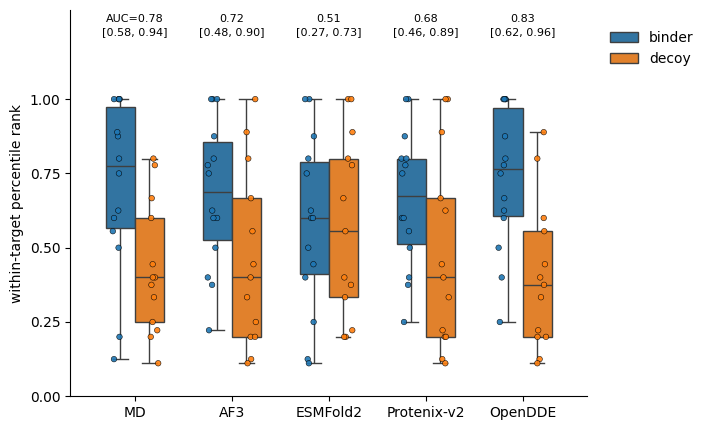

In [11]:
# ---- pooled panel: within-target percentile rank ---------------------------
METHODS = ["MD"] + list(PREDICTORS.values())
SHOW_CI = True
N_BOOT  = 2000

long = pd.concat([
    md.assign(method="MD", score=-md["deltaG"])[["design", "target", "Type", "method", "score"]],
    res.rename(columns={"predictor": "method"})
       .assign(score=lambda d: d["iptm"])[["design", "target", "Type", "method", "score"]],
], ignore_index=True)
long["y"]    = (long.Type == "binder").astype(int)
long["rank"] = long.groupby(["method", "target"])["score"].rank(pct=True)

def rank_auc(g):
    """AUC on within-target percentile ranks, recomputed for whatever rows are passed."""
    return roc_auc_score(g.y, g.groupby("target")["score"].rank(pct=True))

def rank_auc_ci(g, n_boot=N_BOOT, seed=0):
    """Resample designs within target; ranks are recomputed inside each resample."""
    rng, v = np.random.default_rng(seed), []
    for _ in range(n_boot):
        b = pd.concat([s.iloc[rng.integers(0, len(s), len(s))] for _, s in g.groupby("target")])
        if b.y.nunique() < 2:
            continue
        v.append(rank_auc(b))
    return np.percentile(v, [2.5, 97.5])

kw = dict(x="method", y="rank", hue="Type", order=METHODS,
          hue_order=["binder", "decoy"], dodge=True)

fig, ax = plt.subplots(figsize=(7.2, 4.4))
sns.boxplot(long, **kw, showfliers=False, width=0.6, ax=ax)
sns.stripplot(long, **kw, size=4, edgecolor="black", linewidth=0.4,
              alpha=0.9, ax=ax, legend=False)

ax.set_ylim(0, 1.30)                       # headroom for labels
ax.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0]) # but rank only goes to 1

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, m in enumerate(METHODS):
    g = long[long.method == m]
    a = rank_auc(g)
    if SHOW_CI:
        lo, hi = rank_auc_ci(g)
        txt = (f"AUC={a:.2f}\n[{lo:.2f}, {hi:.2f}]" if i == 0
               else f"{a:.2f}\n[{lo:.2f}, {hi:.2f}]")
    else:
        txt = f"AUC={a:.2f}" if i == 0 else f"{a:.2f}"
    ax.text(i, 0.99, txt, transform=trans, ha="center", va="top",
            fontsize=8, linespacing=1.4)

ax.set_xlabel("")
ax.set_ylabel("within-target percentile rank")
ax.margins(x=0.08)

h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc="center left", bbox_to_anchor=(1.02, 0.9),
          frameon=False, title="")

sns.despine(fig)
fig.tight_layout()
plt.show()